# Deep Convolutional Generative Adversarial Network (DCGAN)

### Step 1 - Import libraries

In [1]:
# Tensorflow / Keras
from tensorflow import keras # for building Neural Networks
print('Tensorflow/Keras: %s' % keras.__version__) # print version
from keras.models import Sequential # for assembling a Neural Network model
from keras.layers import Dense, Reshape, Flatten, Conv2D, Conv2DTranspose, ReLU, LeakyReLU, Dropout # adding layers to the Neural Network model
from tensorflow.keras.utils import plot_model # for plotting model diagram
from tensorflow.keras.optimizers import Adam # for model optimization 


# Data manipulation
import numpy as np # for data manipulation
print('numpy: %s' % np.__version__) # print version
import sklearn
print('sklearn: %s' % sklearn.__version__) # print version
from sklearn.preprocessing import MinMaxScaler # for scaling inputs used in the generator and discriminator


# Visualization
import cv2 # for ingesting images
print('OpenCV: %s' % cv2.__version__) # print version
import matplotlib 
import matplotlib.pyplot as plt # or data visualizationa
print('matplotlib: %s' % matplotlib.__version__) # print version
import graphviz # for showing model diagram
print('graphviz: %s' % graphviz.__version__) # print version


# Other utilities
import sys
import os

# Assign main directory to a variable
main_dir=os.path.dirname(sys.path[0])
#print(main_dir)

Tensorflow/Keras: 3.15.1
numpy: 2.3.5
sklearn: 1.7.2
OpenCV: 5.0.0
matplotlib: 3.10.6
graphviz: 0.21


### Step 2 - Load and Process Caltech101 image dataset
- Source and Licence: http://www.vision.caltech.edu/Image_Datasets/Caltech101/
- Required Refrence: L. Fei-Fei, R. Fergus and P. Perona. Learning generative visual models from few training examples: an incremental Bayesian approach tested on 101 object categories. IEEE. CVPR 2004, Workshop on Generative-Model Based Vision. 2004

In [4]:
# Location of Caltech-101 dataset
ImgLocation = r"C:\Users\HP\Downloads\caltech-101\caltech-101\101_ObjectCategories\101_ObjectCategories"

# We want the airplanes category
CATEGORIES = ["airplanes"]

# Create list of image paths
ImagePaths = []

for category in CATEGORIES:
    category_path = os.path.join(ImgLocation, category)

    for image in os.listdir(category_path):
        ImagePaths.append(os.path.join(category_path, image))

# Load images and resize to 64 x 64
data_lowres = []

for img in ImagePaths:
    image = cv2.imread(img)

    # Skip files that OpenCV cannot read
    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_lowres = cv2.resize(image, (64, 64))
    data_lowres.append(image_lowres)

# Convert to NumPy array and normalize to [0, 1]
data_lowres = np.array(data_lowres, dtype="float32") / 255.0

print("Number of images:", len(data_lowres))
print("Shape of data_lowres:", data_lowres.shape)

Number of images: 800
Shape of data_lowres: (800, 64, 64, 3)


##### Display a few real images (64 x 64 pixels)

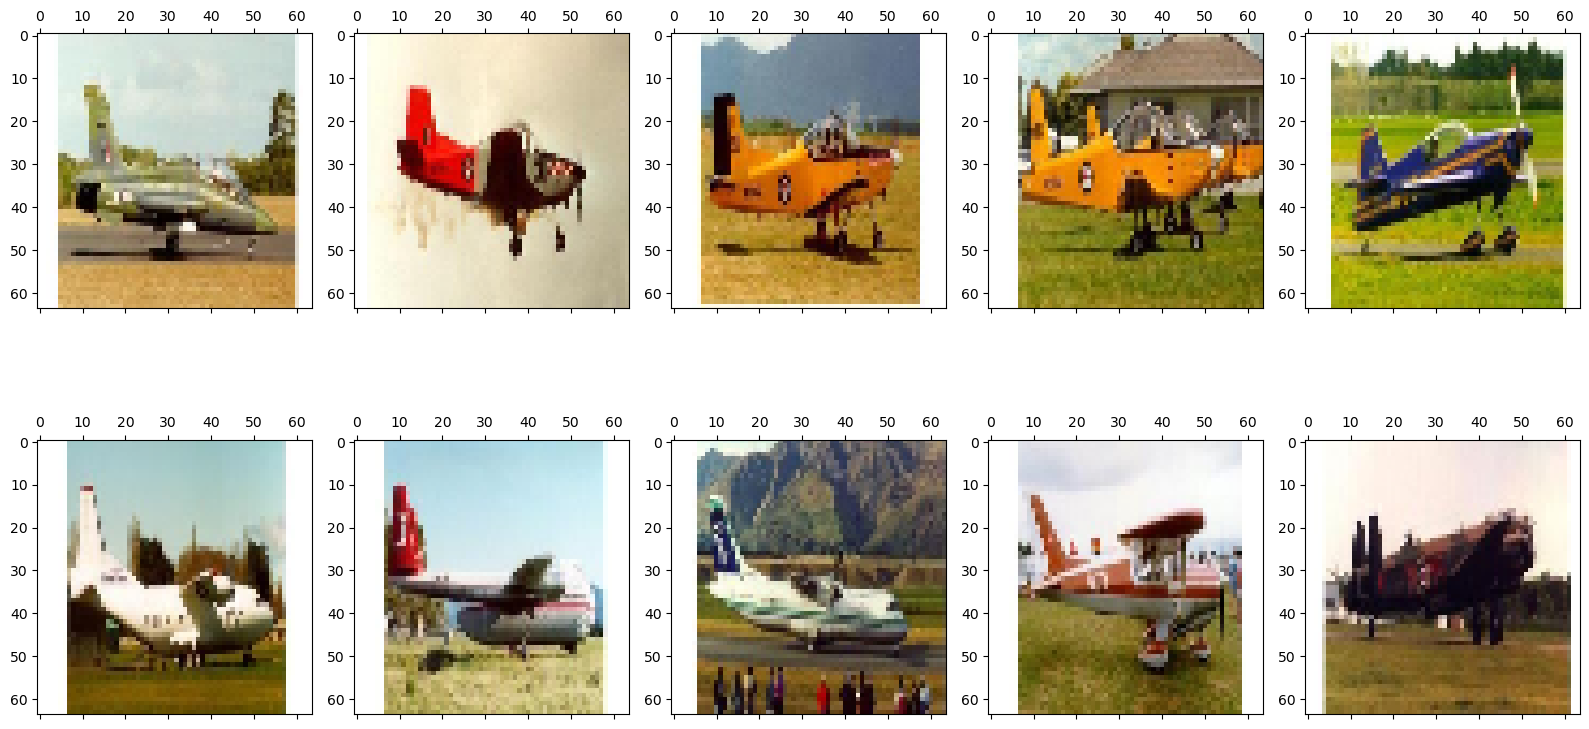

In [5]:
# Display 10 real images
fig, axs = plt.subplots(2, 5, sharey=False, tight_layout=True, figsize=(16,9), facecolor='white')
n=0
for i in range(0,2):
    for j in range(0,5):
        axs[i,j].matshow(data_lowres[n])
        n=n+1
plt.show() 

In [24]:
# Prepare data for DCGAN
data = data_lowres.copy()

print("Original shape of the data:", data.shape)

# Convert pixel values from [0, 1] to [-1, 1]
data = (data * 2.0) - 1.0

print("Shape of the scaled array:", data.shape)
print("Minimum value:", data.min())
print("Maximum value:", data.max())

Original shape of the data: (800, 64, 64, 3)
Shape of the scaled array: (800, 64, 64, 3)
Minimum value: -1.0
Maximum value: 1.0


### Step 3 - Setup GAN

#### Define Generator model

In [63]:
def generator(latent_dim):
    model = Sequential(name="Generator")

    # Start from 8x8x256
    n_nodes = 8 * 8 * 256

    model.add(Dense(n_nodes, input_dim=latent_dim))
    model.add(BatchNormalization())
    model.add(ReLU())
    model.add(Reshape((8, 8, 256)))

    # 8x8 -> 16x16
    model.add(
        Conv2DTranspose(
            128,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # 16x16 -> 32x32
    model.add(
        Conv2DTranspose(
            64,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # 32x32 -> 64x64
    model.add(
        Conv2DTranspose(
            32,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # RGB output
    model.add(
        Conv2D(
            3,
            kernel_size=(5, 5),
            padding="same",
            activation="tanh"
        )
    )

    return model


latent_dim = 100
gen_model = generator(latent_dim)

gen_model.summary()

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 16384)               │       1,654,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 16384)               │          65,536 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_12 (ReLU)                      │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_3 (Reshape)                  │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_9 (Conv2DTranspose) │ (None, 16, 16, 128)         │         524,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_13 (ReLU)                      │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_10                  │ (None, 32, 32, 64)          │         131,136 │
│ (Conv2DTranspose)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_14 (ReLU)                      │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_11                  │ (None, 64, 64, 32)          │          32,800 │
│ (Conv2DTranspose)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_15 (ReLU)                      │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 64, 64, 3)           │           2,403 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,411,971 (9.20 MB)

 Trainable params: 2,378,755 (9.07 MB)

 Non-trainable params: 33,216 (129.75 KB)

#### Define a Discriminator model

In [65]:
from tensorflow.keras import Input
def discriminator(in_shape=(64, 64, 3)):

    model = Sequential(name="Discriminator")

    # Input: 64x64 RGB image
    model.add(Input(shape=in_shape))

    # 64x64 -> 32x32
    model.add(
        Conv2D(
            64,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    # 32x32 -> 16x16
    model.add(
        Conv2D(
            128,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    # 16x16 -> 8x8
    model.add(
        Conv2D(
            256,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dropout(0.3))

    # Classification
    model.add(Flatten())
    model.add(Dense(1, activation="sigmoid"))

    # Compile
    model.compile(
        loss="binary_crossentropy",
        optimizer=Adam(
            learning_rate=0.0002,
            beta_1=0.5
        ),
        metrics=["accuracy"]
    )

    return model


dis_model = discriminator()
dis_model.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)                    │ (None, 32, 32, 64)          │           3,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 16, 16, 128)         │         131,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_4 (LeakyReLU)            │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 8, 8, 256)           │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_5 (LeakyReLU)            │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │          16,385 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 675,265 (2.58 MB)

 Trainable params: 675,265 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [66]:
from tensorflow.keras.layers import BatchNormalization

In [67]:
from tensorflow.keras.layers import (
    Dense,
    Reshape,
    Conv2D,
    Conv2DTranspose,
    ReLU,
    LeakyReLU,
    Flatten,
    Dropout,
    BatchNormalization
)

#### Combine Generator and Discriminator models into trainable GAN

In [68]:
def generator(latent_dim):
    model = Sequential(name="Generator")

    # Start: 8x8x256
    n_nodes = 8 * 8 * 256

    model.add(Dense(n_nodes, input_dim=latent_dim))
    model.add(BatchNormalization())
    model.add(ReLU())
    model.add(Reshape((8, 8, 256)))

    # 8x8 -> 16x16
    model.add(
        Conv2DTranspose(
            128,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # 16x16 -> 32x32
    model.add(
        Conv2DTranspose(
            64,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # 32x32 -> 64x64
    model.add(
        Conv2DTranspose(
            32,
            kernel_size=(4, 4),
            strides=(2, 2),
            padding="same"
        )
    )
    model.add(BatchNormalization())
    model.add(ReLU())

    # RGB output
    model.add(
        Conv2D(
            3,
            kernel_size=(5, 5),
            padding="same",
            activation="tanh"
        )
    )

    return model


latent_dim = 100
gen_model = generator(latent_dim)

gen_model.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 16384)               │       1,654,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_16               │ (None, 16384)               │          65,536 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_16 (ReLU)                      │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_4 (Reshape)                  │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_12                  │ (None, 16, 16, 128)         │         524,416 │
│ (Conv2DTranspose)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_17               │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_17 (ReLU)                      │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_13                  │ (None, 32, 32, 64)          │         131,136 │
│ (Conv2DTranspose)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_18               │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_18 (ReLU)                      │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_14                  │ (None, 64, 64, 32)          │          32,800 │
│ (Conv2DTranspose)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_19               │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_19 (ReLU)                      │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 64, 64, 3)           │           2,403 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,411,971 (9.20 MB)

 Trainable params: 2,378,755 (9.07 MB)

 Non-trainable params: 33,216 (129.75 KB)

### Step 4 - Setup functions to:
- sample the latent space 
- sample real images
- generate fake images with the generator model

##### Set up a function to sample real images

In [69]:
def real_samples(n, dataset):
    
    # Samples of real data
    X = dataset[np.random.choice(dataset.shape[0], n, replace=True), :]

    # Class labels
    y = np.ones((n, 1))

    return X, y

##### Generate points in the latent space, which we will use as inputs for the generator

In [70]:
def latent_vector(latent_dim, n):
    
    # Generate points in the latent space
    latent_input = np.random.randn(latent_dim * n)
    
    # Reshape into a batch of inputs for the network
    latent_input = latent_input.reshape(n, latent_dim)
    return latent_input

##### The below function will use the generator to generate n fake examples together with class labels

In [71]:
def fake_samples(generator, latent_dim, n):
    
    # Generate points in latent space
    latent_output = latent_vector(latent_dim, n)
    
    # Predict outputs (i.e., generate fake samples)
    X = generator.predict(latent_output)
    
    # Create class labels
    y = np.zeros((n, 1))
    return X, y

In [98]:
def build_gan(generator, discriminator):

    # Freeze discriminator only inside GAN
    discriminator.trainable = False

    model = Sequential(name="GAN")

    model.add(generator)
    model.add(discriminator)

    model.compile(
        loss="binary_crossentropy",
        optimizer=Adam(
            learning_rate=0.0002,
            beta_1=0.5
        )
    )

    return model


gan_model = build_gan(gen_model, dis_model)

gan_model.summary()

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Generator (Sequential)               │ (None, 64, 64, 3)           │       2,411,971 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Discriminator (Sequential)           │ (None, 1)                   │         675,265 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,087,236 (11.78 MB)

 Trainable params: 2,378,755 (9.07 MB)

 Non-trainable params: 708,481 (2.70 MB)

### Step 5 - Setup functions for model performance evaluation and training

##### Show Discriminator model accuracy and plot real vs. fake (generated) comparison

In [99]:
def performance_summary(generator, discriminator, dataset, latent_dim, n=6):

    # Real images
    x_real, y_real = real_samples(n, dataset)
    _, real_accuracy = discriminator.evaluate(x_real, y_real, verbose=0)

    # Fake images
    x_fake, y_fake = fake_samples(generator, latent_dim, n)
    _, fake_accuracy = discriminator.evaluate(x_fake, y_fake, verbose=0)

    print("*** Evaluation ***")
    print("Discriminator Accuracy on REAL images:", real_accuracy)
    print("Discriminator Accuracy on FAKE (generated) images:", fake_accuracy)

    # Convert generated images from [-1, 1] back to [0, 1]
    x_fake_display = (x_fake + 1.0) / 2.0
    x_fake_display = np.clip(x_fake_display, 0, 1)

    # Display 6 generated RGB images
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))

    for k, ax in enumerate(axes.flat):
        ax.imshow(x_fake_display[k])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

##### Define a function to train our DCGAN model (generator and discriminator)

In [100]:
def train(
    g_model,
    d_model,
    gan_model,
    dataset,
    latent_dim,
    n_epochs=800,
    n_batch=32,
    n_eval=100
):

    half_batch = n_batch // 2

    for i in range(n_epochs):

        # =====================================
        # 1. TRAIN DISCRIMINATOR
        # =====================================

        # Real images
        x_real, y_real = real_samples(
            half_batch,
            dataset
        )

        # Fake images
        x_fake, y_fake = fake_samples(
            g_model,
            latent_dim,
            half_batch
        )

        # Combine real + fake
        X = np.vstack((x_real, x_fake))
        y = np.vstack((y_real, y_fake))

        # Train discriminator
        d_result = d_model.train_on_batch(X, y)

        if isinstance(d_result, (list, tuple)):
            discriminator_loss = d_result[0]
            discriminator_accuracy = d_result[1]
        else:
            discriminator_loss = d_result
            discriminator_accuracy = 0.0

        # =====================================
        # 2. TRAIN GENERATOR
        # =====================================

        # Random latent vectors
        x_gan = latent_vector(
            latent_dim,
            n_batch
        )

        # Generator wants discriminator
        # to classify generated images as REAL
        y_gan = np.ones(
            (n_batch, 1)
        )

        generator_loss = gan_model.train_on_batch(
            x_gan,
            y_gan
        )

        # If Keras returns a list, take the loss
        if isinstance(generator_loss, (list, tuple)):
            generator_loss = generator_loss[0]

        # =====================================
        # 3. EVALUATE
        # =====================================

        if i % n_eval == 0:

            print("\n==============================")
            print("Epoch:", i)
            print("==============================")

            print(
                "Discriminator Loss:",
                float(discriminator_loss)
            )

            print(
                "Discriminator Accuracy:",
                float(discriminator_accuracy)
            )

            print(
                "Generator Loss:",
                float(generator_loss)
            )

            performance_summary(
                g_model,
                d_model,
                dataset,
                latent_dim,
                n=6
            )

### Step 6 - Train the model and plot the results

##### Use the above train function to train our GAN model

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


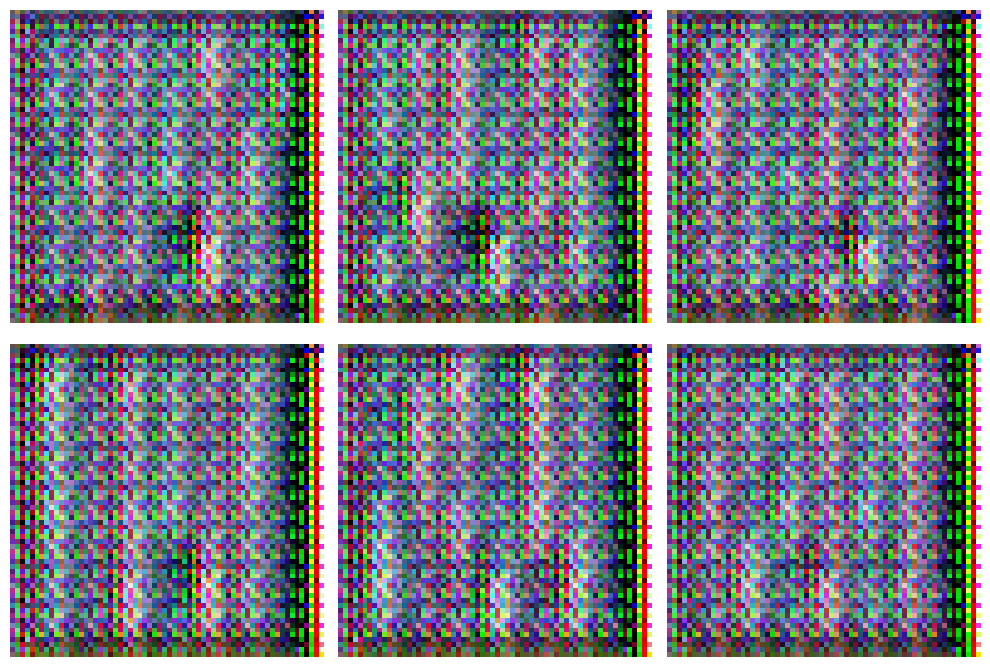

In [103]:
np.random.seed(42)

x_fake, _ = fake_samples(gen_model, latent_dim, 6)

x_fake_display = (x_fake + 1.0) / 2.0
x_fake_display = np.clip(x_fake_display, 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for k, ax in enumerate(axes.flat):
    ax.imshow(x_fake_display[k])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [104]:
# Create the combined GAN model

dis_model.trainable = False

gan_model = Sequential(name="GAN")

gan_model.add(gen_model)
gan_model.add(dis_model)

gan_model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(
        learning_rate=0.0002,
        beta_1=0.5
    )
)

print("GAN created successfully")
gan_model.summary()

GAN created successfully


Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Generator (Sequential)               │ (None, 64, 64, 3)           │       2,411,971 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Discriminator (Sequential)           │ (None, 1)                   │         675,265 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,087,236 (11.78 MB)

 Trainable params: 2,378,755 (9.07 MB)

 Non-trainable params: 708,481 (2.70 MB)

In [105]:
# Make discriminator trainable for its own training
dis_model.trainable = True

dis_model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    metrics=["accuracy"]
)

# Freeze discriminator again inside GAN
dis_model.trainable = False

gan_model = Sequential(name="GAN")
gan_model.add(gen_model)
gan_model.add(dis_model)

gan_model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(
        learning_rate=0.0002,
        beta_1=0.5
    )
)

print("GAN ready for training!")

GAN ready for training!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step

Epoch: 0
Discriminator Loss: 2.9869210720062256
Discriminator Accuracy: 0.5
Generator Loss: 0.0002725645317696035
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
*** Evaluation ***
Discriminator Accuracy on REAL images: 1.0
Discriminator Accuracy on FAKE (generated) images: 0.0


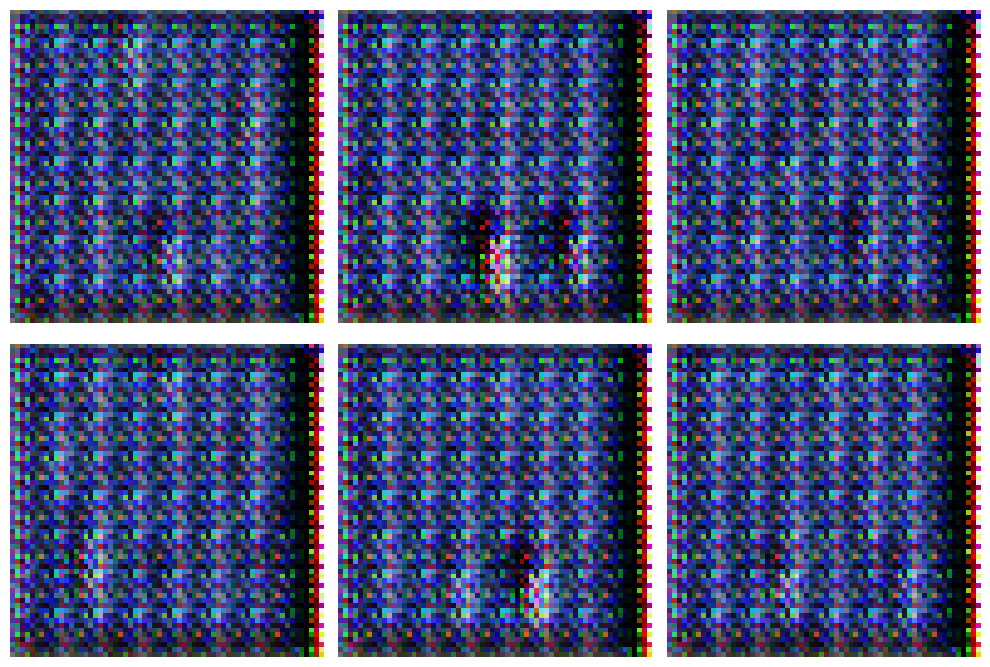

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━

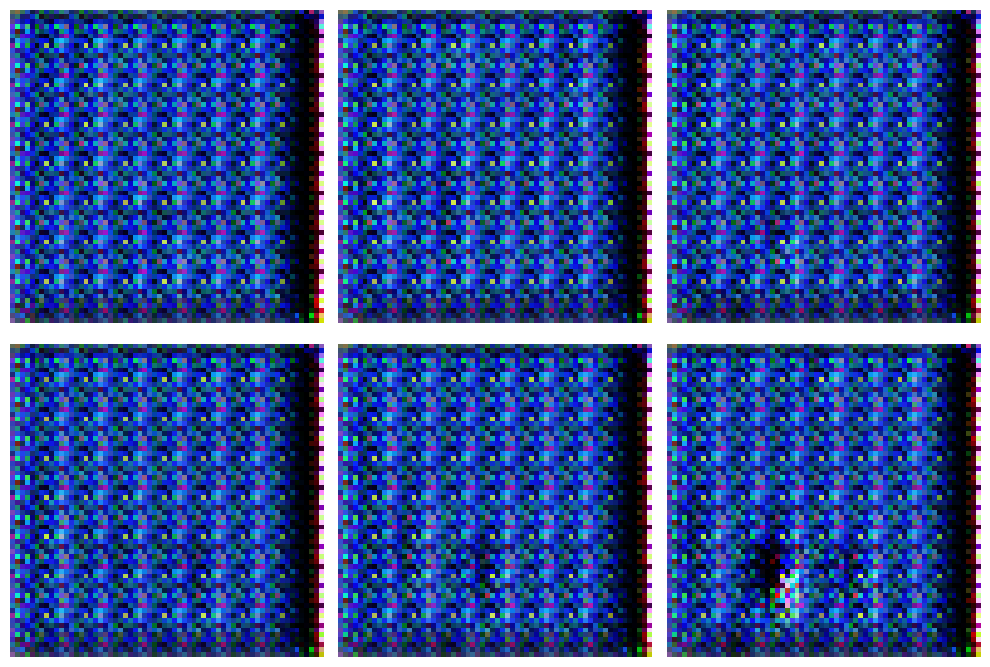

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━

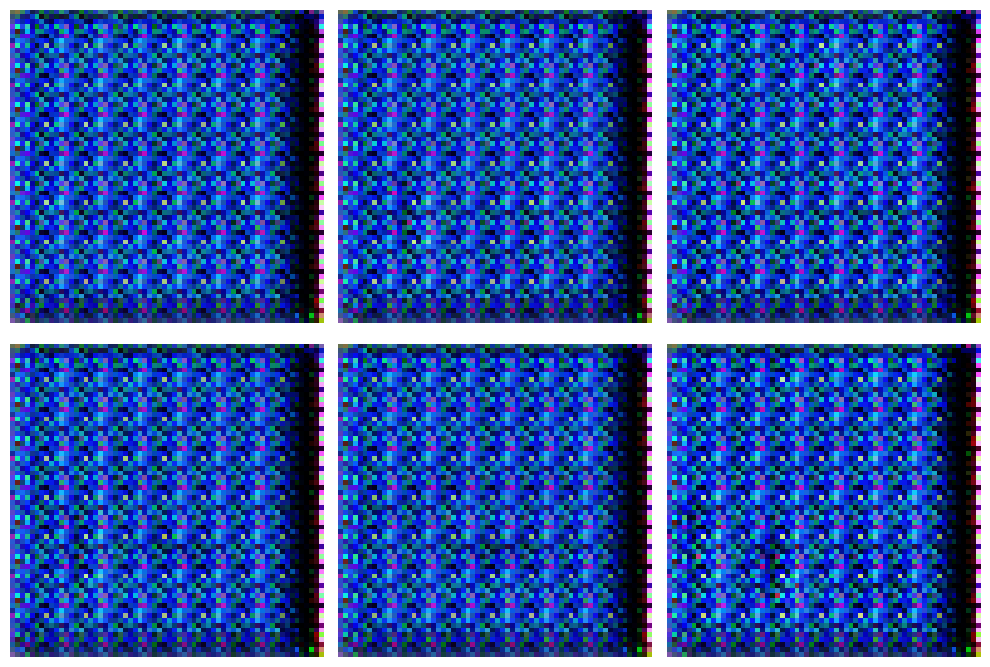

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━

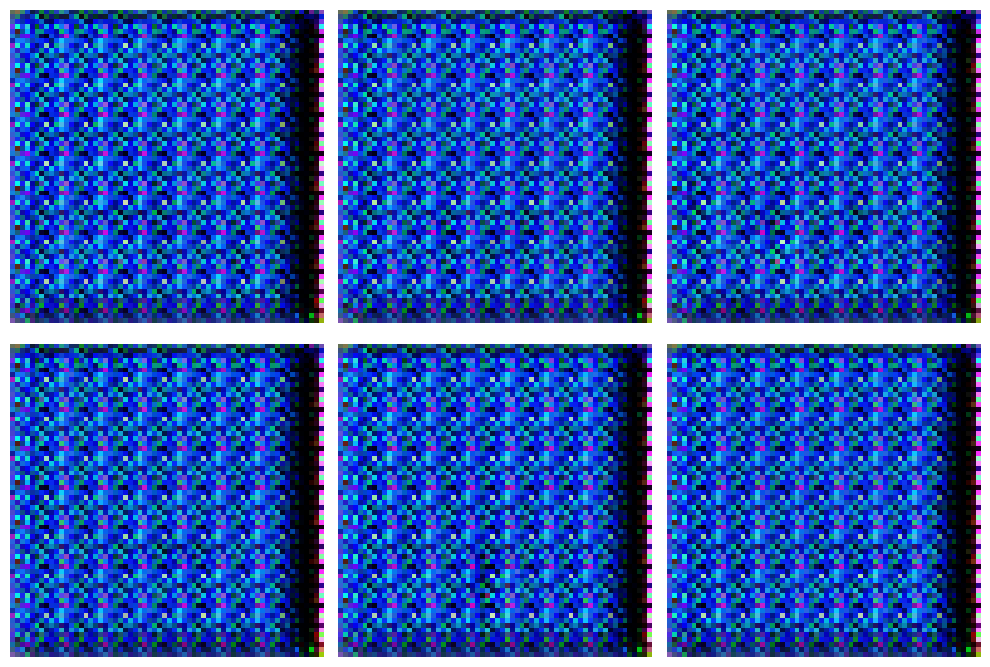

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━

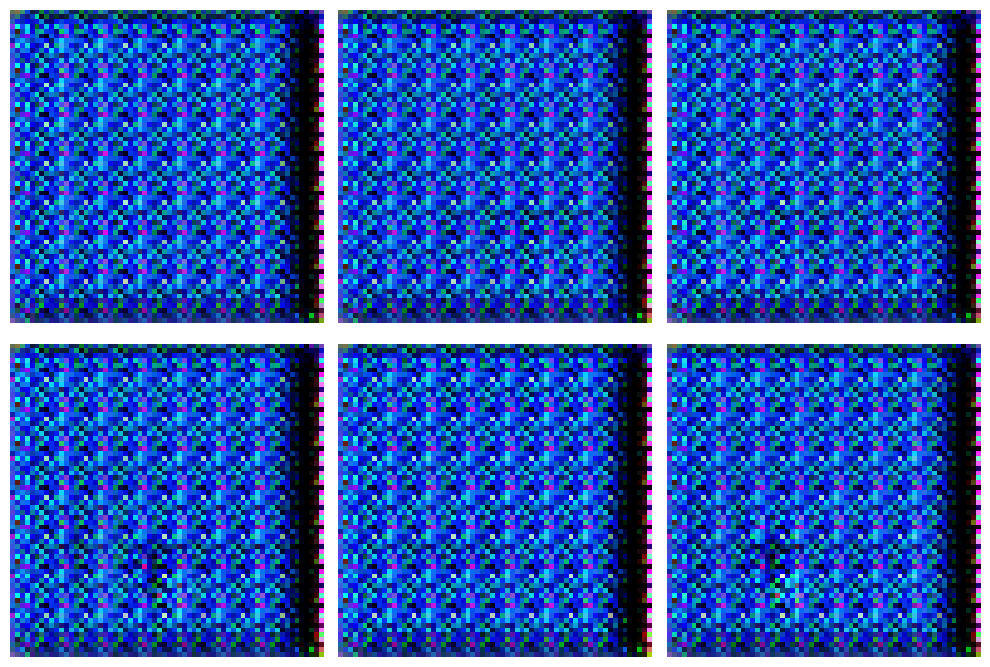

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━

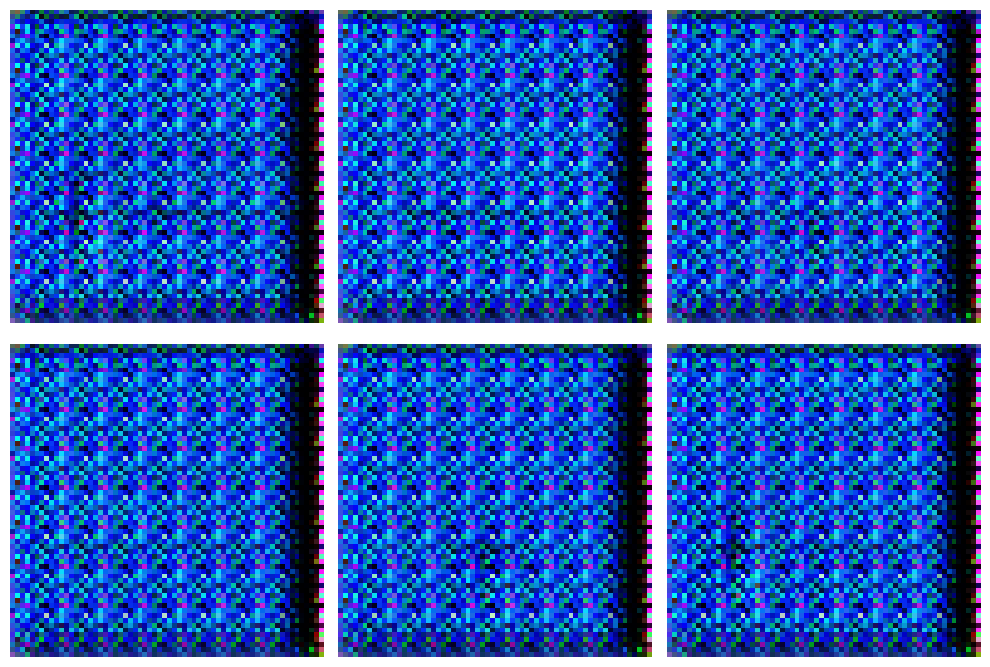

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━

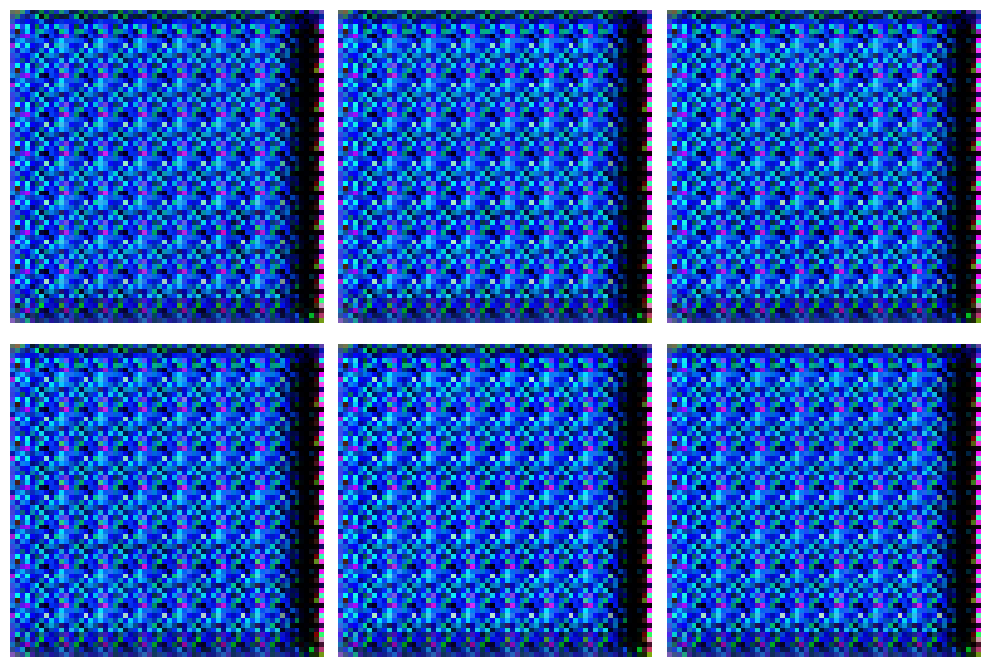

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━

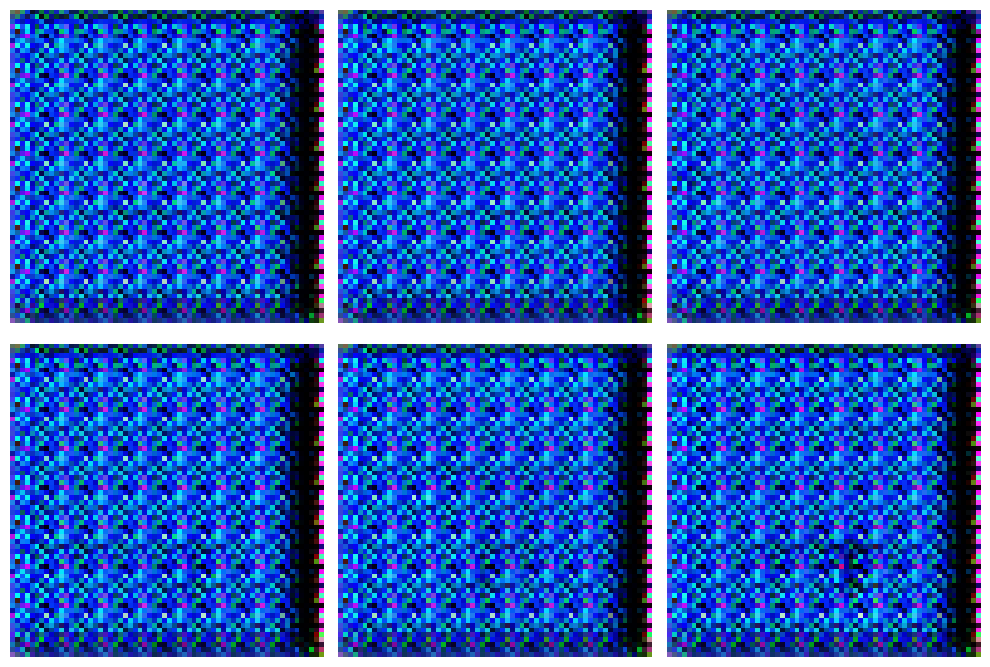

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━

In [107]:
# Train for 800 epochs
train(
    gen_model,
    dis_model,
    gan_model,
    data,
    latent_dim,
    n_epochs=800,
    n_eval=100
)

##### Example how to load a previously saved model

In [108]:
# Add library
# from keras.models import load_model
# Load saved models
# gen_model = load_model(main_dir+"/data/models/007b_Generator_3k.h5")
# dis_model = load_model(main_dir+"/data/models/007b_Discriminator_3k.h5")
# gan_model = load_model(main_dir+"/data/models/007b_GAN_3k.h5")

---

### Step 7 - Evaluate model performace and use the Generator to create a bunch of images 

In [109]:
def performance_eval(epoch, generator, discriminator, dataset, latent_dim, n=40):
    
    # Get samples of the real data
    x_real, y_real = real_samples(n, dataset)
    # Evaluate the descriminator on real data
    _, real_accuracy = discriminator.evaluate(x_real, y_real, verbose=0)
    
    # Get fake (generated) samples
    x_fake, y_fake = fake_samples(generator, latent_dim, n)
    # Evaluate the descriminator on fake (generated) data
    _, fake_accuracy = discriminator.evaluate(x_fake, y_fake, verbose=0)
    
    # summarize discriminator performance
    print("Epoch number: ", epoch)
    print("Discriminator Accuracy on REAL images: ", real_accuracy)
    print("Discriminator Accuracy on FAKE (generated) images: ", fake_accuracy)
    
    # Create a 2D scatter plot to show real and fake (generated) data points
    # Display 20 fake images
    # Display 6 fake images
    x_fake_inv_trans=x_fake.reshape(-1, 1)
    x_fake_inv_trans=scaler.inverse_transform(x_fake_inv_trans)
    x_fake_inv_trans=x_fake_inv_trans.reshape(n, 64, 64, 3)
    
    fig, axs = plt.subplots(8, 5, sharey=False, tight_layout=True, figsize=(48,48), facecolor='white')
    k=0
    for i in range(0,8):
        for j in range(0,5):
            axs[i,j].matshow(x_fake_inv_trans[k])
            k=k+1
    plt.show() 

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Epoch number:  0
Discriminator Accuracy on REAL images:  1.0
Discriminator Accuracy on FAKE (generated) images:  0.0


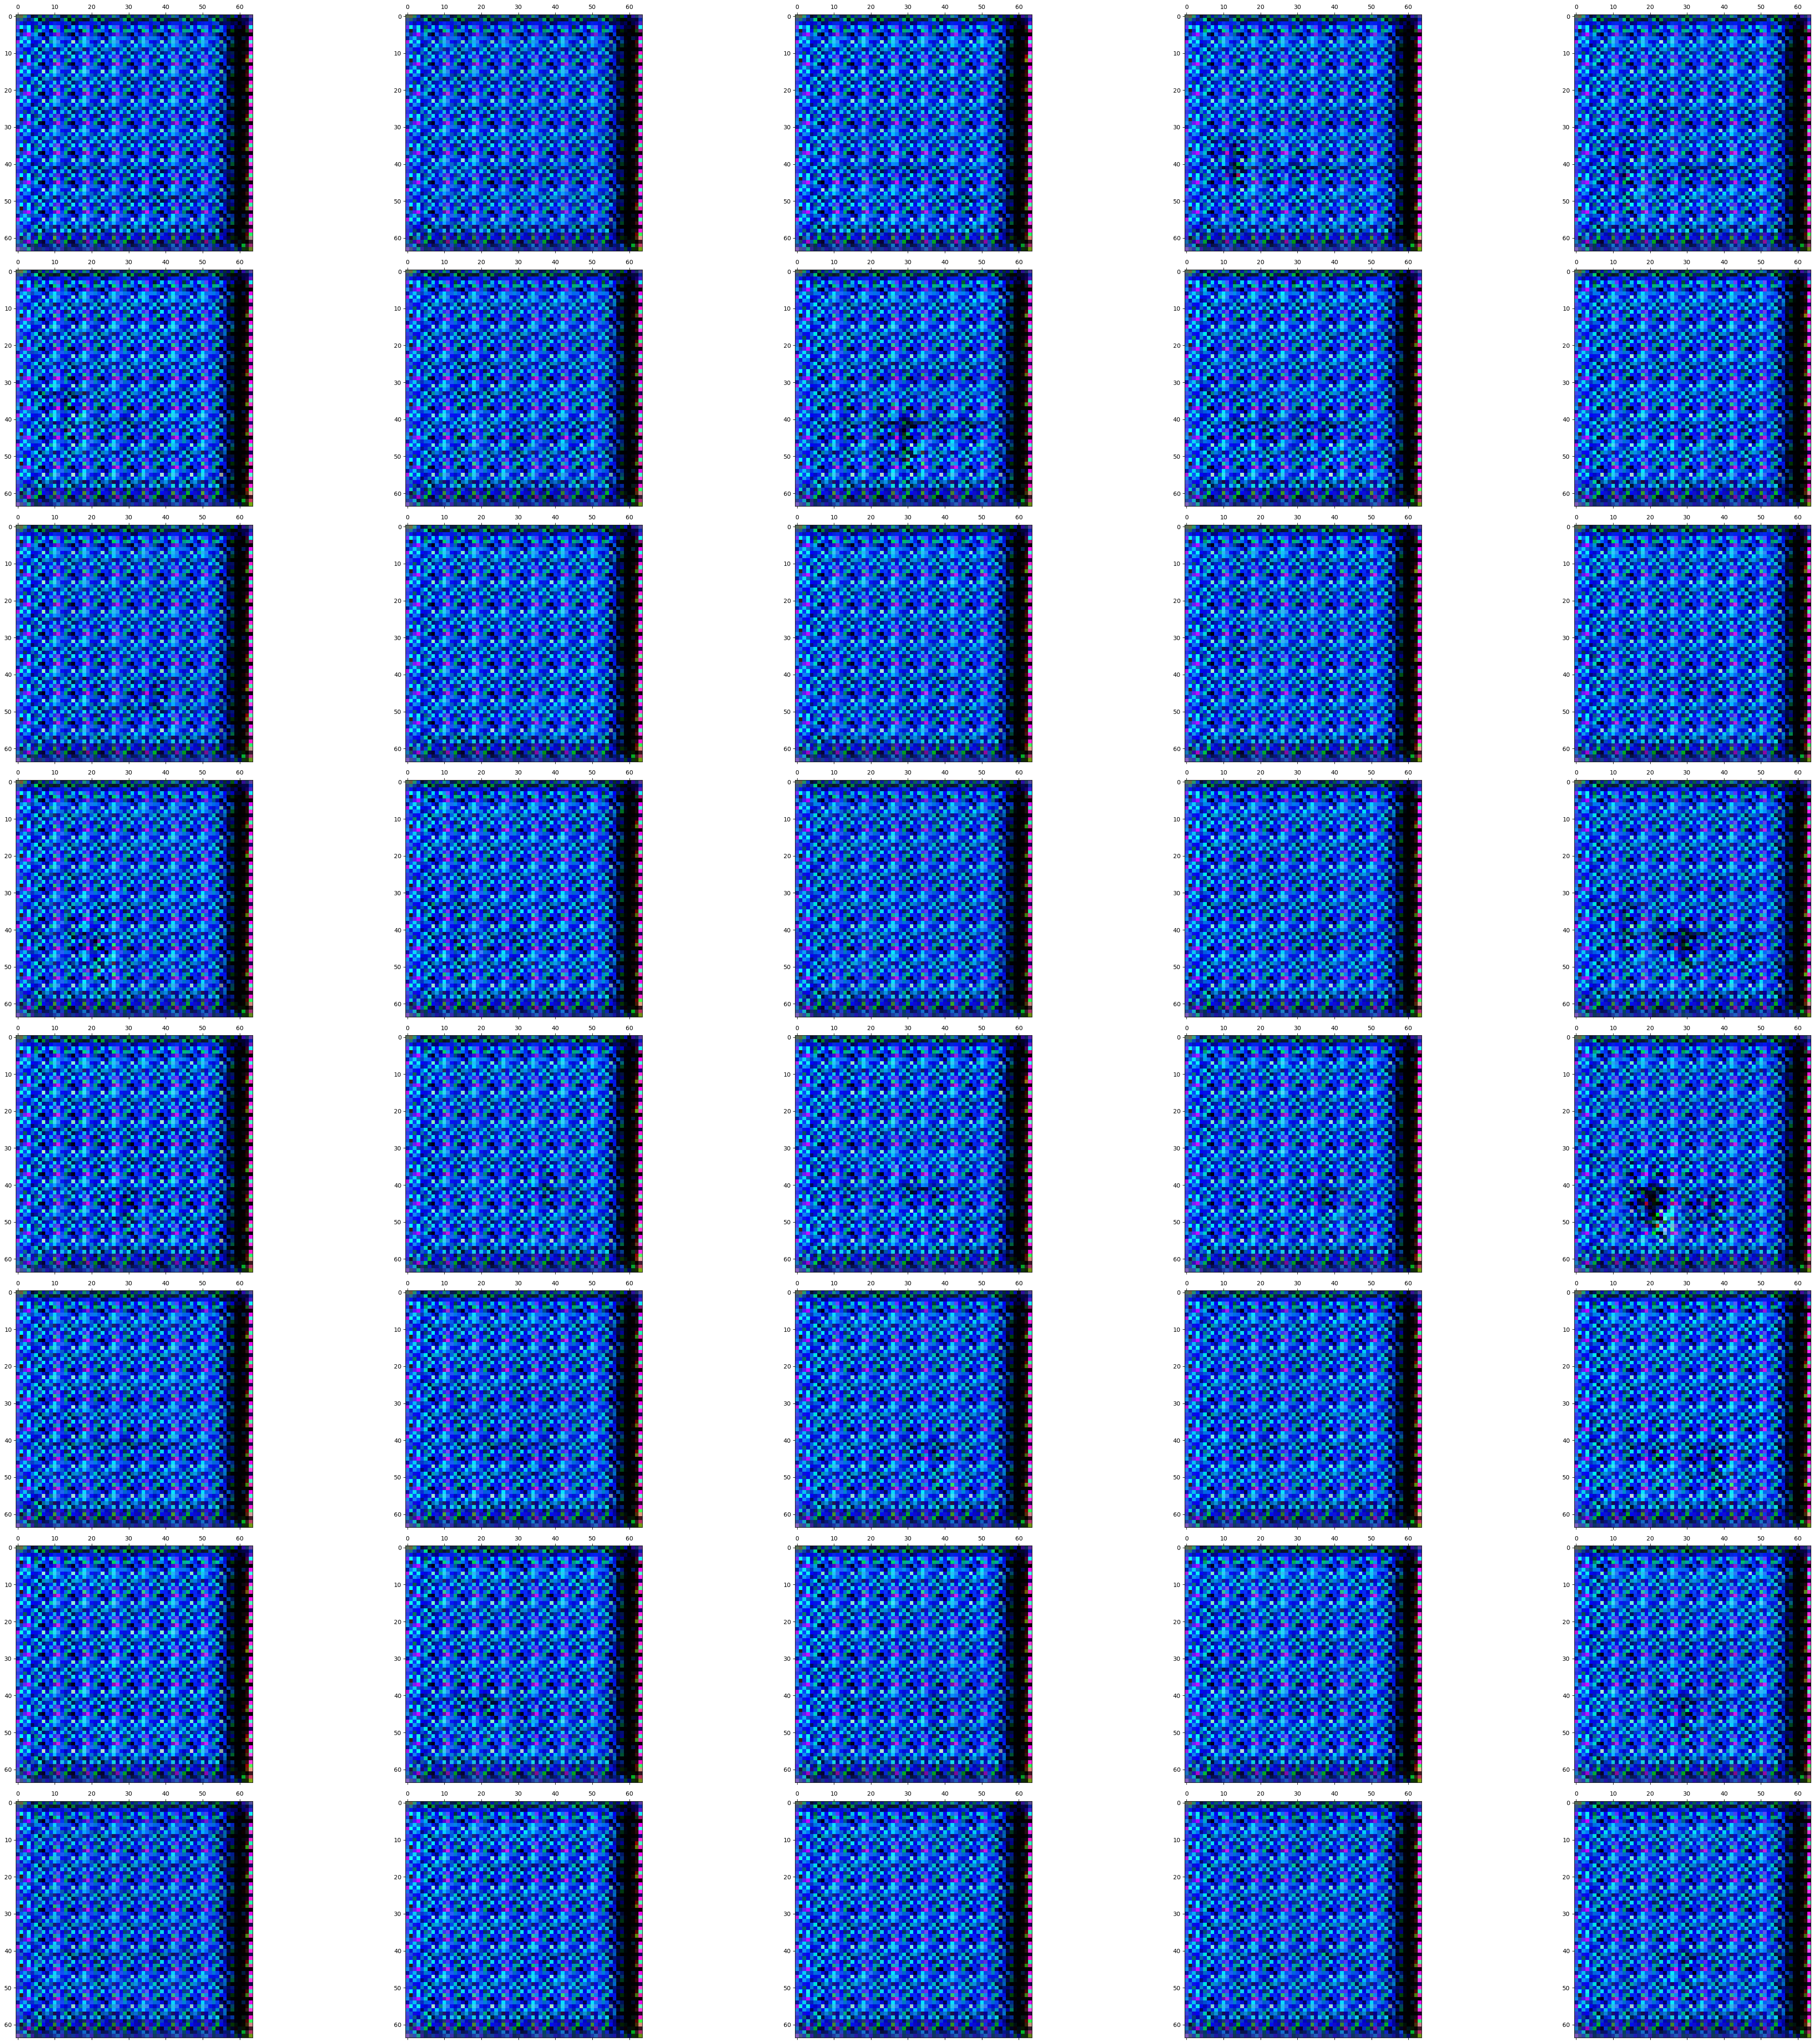

In [110]:
# After 2K epochs
performance_eval(0, gen_model, dis_model, data, 100)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Epoch number:  0
Discriminator Accuracy on REAL images:  1.0
Discriminator Accuracy on FAKE (generated) images:  0.0


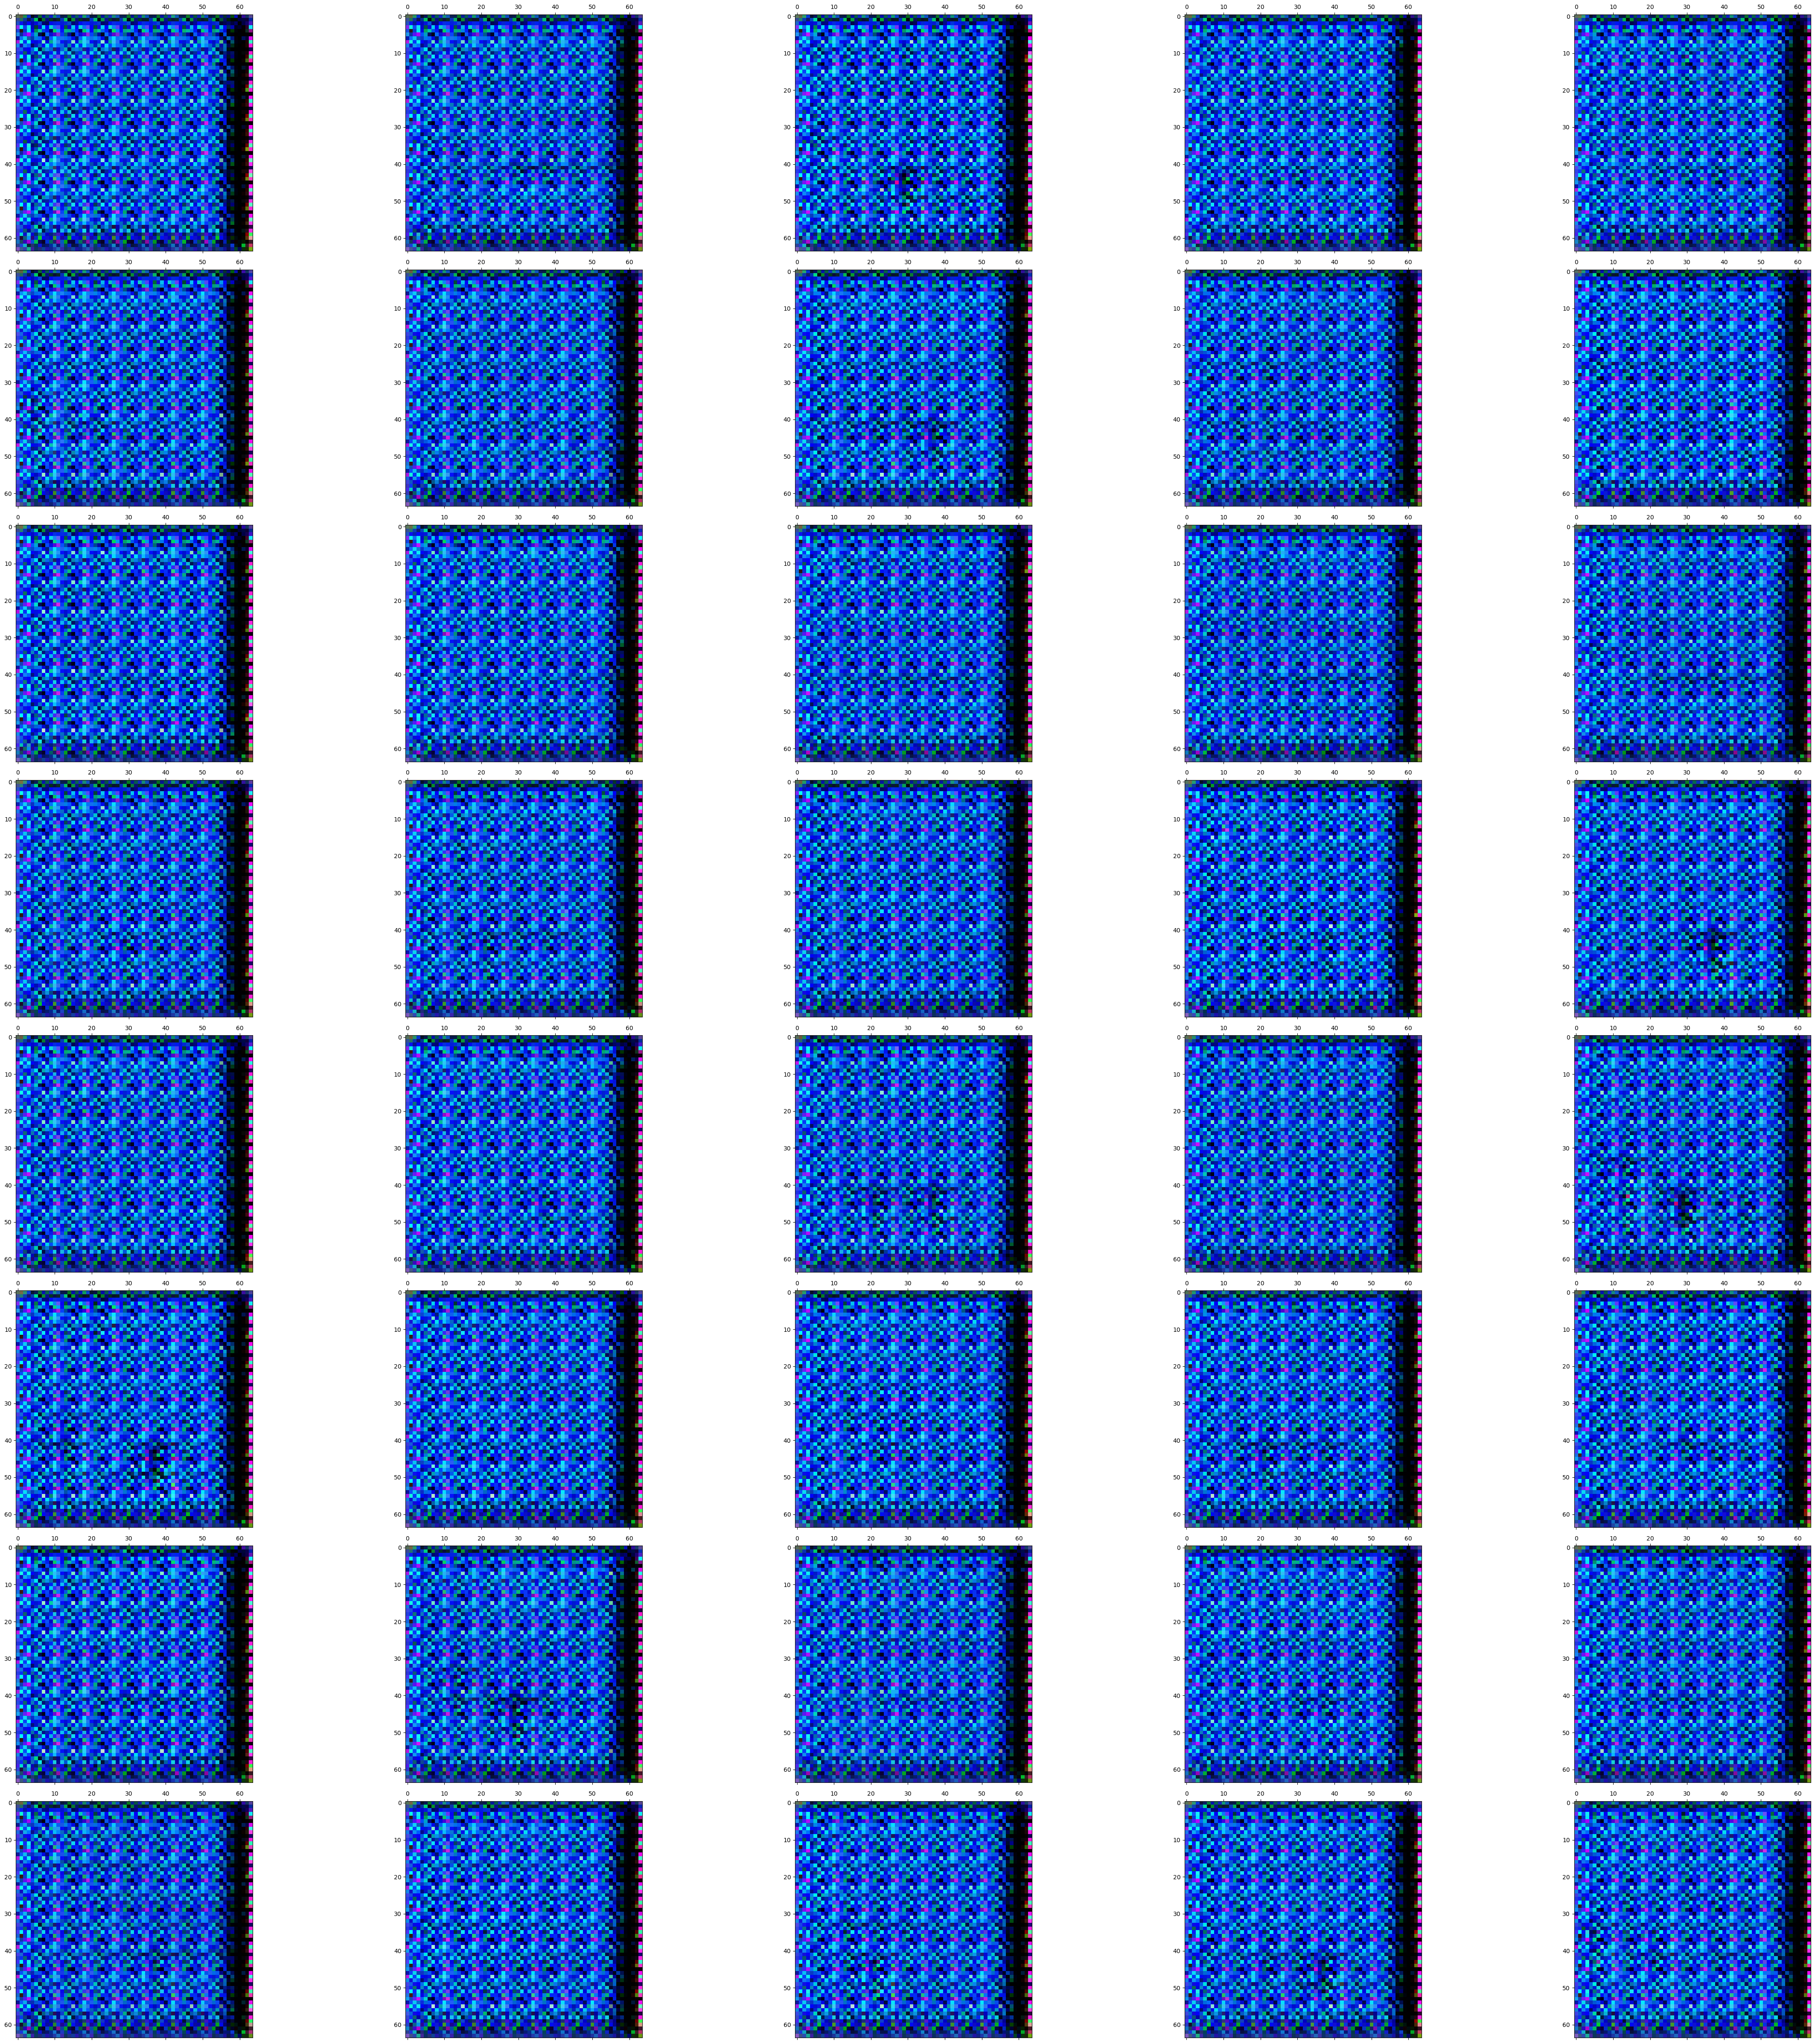

In [111]:
# After 3K epochs
performance_eval(0, gen_model, dis_model, data, 100)

---

### Appendix - Generate one random Image

In [112]:
# Generate an image of a bonsai tree using random latent vector
x_fake, y_fake = fake_samples(gen_model, 100, 1)

# Shape and inverse transpose the generated image
x_fake_inv_trans=x_fake.reshape(-1, 1)
x_fake_inv_trans=scaler.inverse_transform(x_fake_inv_trans)
x_fake_inv_trans=x_fake_inv_trans.reshape(64, 64, 3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


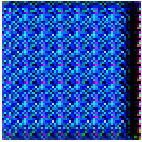

In [113]:
# Show the generated image
fig, ax = plt.subplots(figsize=(16,9), dpi=20)
ax.matshow(x_fake_inv_trans)
plt.axis('off')
plt.show()

# End of Program